# Sincronización de células marcapasos: Kuramoto contra Winfree

Simulación de 400 osciladores de fase que representan células marcapasos del nodo sinoauricular, con dos modelos clásicos de sincronización: Kuramoto (acoplamiento continuo y sinusoidal) y Winfree (acoplamiento pulsátil que depende de la fase). Se mide cómo surge la sincronía al aumentar la fuerza de acoplamiento y se contrasta con el valor crítico que predice la teoría.

Autores: Santiago Castellanos, Catalina Gutiérrez y Camilo Millán.

## 1. Introducción

La sincronización es un fenómeno fundamental en la naturaleza que ocurre cuando sistemas oscilatorios individuales ajustan sus ritmos para alcanzar un comportamiento colectivo coordinado. Este fenómeno puede observarse en diversos contextos: desde el destello simultáneo de luciérnagas, hasta el latido coordinado del corazón humano, pasando por la propagación de aplausos en un auditorio.

Comprender matemáticamente cómo surge la sincronización a partir de componentes individuales sin coordinación central es uno de los grandes desafíos de la teoría de sistemas complejos. Dos modelos matemáticos han sido fundamentales en este campo: el modelo de Winfree (1967) y el modelo de Kuramoto (1975). Ambos han revolucionado nuestra comprensión de la sincronización, pero desde perspectivas complementarias.

En este trabajo se presenta una comparación entre ambos modelos, con sus fundamentos y simulaciones numéricas. Para ilustrar su aplicabilidad, **se implementan ambos modelos en el contexto de las células marcapasos cardíacas del nodo sinoauricular**, un sistema biológico donde la sincronización es literalmente una cuestión de vida o muerte.

## 2. Contexto: células marcapasos del nodo sinoauricular

El corazón humano late aproximadamente 100,000 veces al día gracias a un sofisticado sistema de células especializadas ubicadas en el nodo sinoauricular (SA). Este pequeño grupo de células, que mide apenas unos milímetros, contiene aproximadamente 10,000 células marcapasos que funcionan como osciladores biológicos naturales.

Cada célula marcapasos posee su propia frecuencia intrínseca de disparo, es decir, si estuviera aislada, generaría impulsos eléctricos a su propio ritmo particular. Sin embargo, en condiciones normales, estas células están acopladas eléctricamente mediante uniones comunicantes (gap junctions) que permiten el flujo de corrientes iónicas entre células vecinas. Este acoplamiento produce un fenómeno emergente extraordinario: todas las células "negocian" y terminan disparando de forma sincronizada, generando el ritmo sinusal regular que caracteriza a un corazón sano.

En las simulaciones, cada oscilador es una célula, su frecuencia natural ω es la velocidad a la que dispararía sola, el acoplamiento K representa la fuerza de las conexiones eléctricas y la sincronización ocurre cuando todas las células laten en fase.

## 3. Los dos modelos

### Modelo de Winfree

Arthur Winfree, considerado el padre de la teoría moderna de sincronización biológica, propuso el primer modelo matemático riguroso para describir cómo poblaciones de osciladores biológicos pueden sincronizarse espontáneamente.

$$\frac{d\theta_i}{dt} = \omega_i + \frac{K}{N} \sum_{j=1}^{N} P(\theta_j) Z(\theta_i)$$

Donde:

    - θᵢ: Fase del oscilador i (posición en su ciclo, de 0 a 2π)

    - ωᵢ: Frecuencia natural del oscilador i

    - K: Constante de acoplamiento (fuerza de interacción)

    - N: Número total de osciladores

    - P(θⱼ): Función de pulso (cuánta influencia emite el oscilador j)

    - Z(θᵢ): Función de sensibilidad (cuán receptivo está el oscilador i)

En este trabajo se usan P(θ) = 1 + cos θ (pulso máximo en θ = 0, nunca negativo) y Z(θ) = 1 − cos θ.


**En el contexto cardíaco:**

- P(θⱼ) modelaría la corriente eléctrica que genera una célula durante su despolarización
- Z(θᵢ) representaría la susceptibilidad de una célula a ser influenciada según su estado en el ciclo

**Características clave:**

- Acoplamiento pulsátil: El modelo asume que los osciladores se influyen mediante "eventos discretos" (pulsos), lo cual es muy realista para sistemas como neuronas (potenciales de acción) o células marcapasos (despolarizaciones rápidas).
- Flexibilidad funcional: Las funciones P(θ) y Z(θ) pueden ajustarse para capturar diferentes mecanismos biológicos de acoplamiento.
- No linealidad intrínseca: Desde su formulación, el modelo contempla comportamientos no lineales complejos.
- Desafío matemático: La forma general del modelo hace difícil obtener soluciones analíticas, requiriendo principalmente simulación numérica.

### Modelo de Kuramoto

Yoshiki Kuramoto simplificó el enfoque de Winfree al asumir que el acoplamiento es sinusoidal y débil, resultando en un modelo matemáticamente elegante y tratable.

$$\frac{d\theta_i}{dt} = \omega_i + \frac{K}{N} \sum_{j=1}^{N} \sin(\theta_j - \theta_i)$$

Donde:

    - θᵢ: Fase del oscilador i (posición en su ciclo, de 0 a 2π)

    - ωᵢ: Frecuencia natural del oscilador i

    - K: Constante de acoplamiento (fuerza de interacción)

    - N: Número total de osciladores

**En el contexto cardíaco:**

- El término sin(θⱼ - θᵢ) representa la corriente iónica que fluye continuamente entre células a través de gap junctions.
- Es una aproximación válida cuando las células están en regímenes de oscilación suave.

**Características clave:**

- Simplicidad matemática: La forma sinusoidal permite derivar soluciones analíticas y predicciones teóricas precisas.
- Parámetro de Orden ($r$): Se puede definir una medida cuantitativa de sincronización: **$r$** ($\text{entre } 0 \text{ y } 1$) mide el grado de coherencia o sincronización de las fases.
    * Si $r \approx 0$, los osciladores están desincronizados (sus fases son aleatorias).
    * Si $r \approx 1$, los osciladores están completamente sincronizados (sus fases son casi idénticas).
- Transición de fase: Existe un valor crítico Kc donde la población transita abruptamente de desincronización a sincronización.
- Acoplamiento continuo: Asume interacciones suaves y permanentes entre osciladores.



Para frecuencias naturales con distribución normal de desviación σ, la teoría de Kuramoto predice el acoplamiento crítico

$$K_c = \frac{2}{\pi g(0)} = \sigma\sqrt{\frac{8}{\pi}}$$

donde g(0) es la densidad de las frecuencias en su centro. Con σ = 0,5, $K_c \approx 0{,}80$.

### Diferencias

Comparativa: Modelos de Sincronización (Winfree vs. Kuramoto)

| Aspecto | Modelo de **Winfree** | Modelo de **Kuramoto** |
| :--- | :--- | :--- |
| **Año de propuesta** | 1967 | 1975 |
| **Tipo de acoplamiento** | Pulsátil, discreto | Continuo, sinusoidal |
| **Complejidad matemática** | Alta, no lineal general | Moderada, no lineal específica |
| **Soluciones analíticas** | Limitadas | Abundantes |
| **Realismo biológico** | Alto (eventos discretos) | Medio (aproximación continua) |
| **Flexibilidad** | Alta ($P$ y $Z$ ajustables) | Limitada (forma fija: $\sin(\theta_j - \theta_i)$) |
| **Costo computacional** | Mayor | Menor |
| **Predicción de $K_c$** | Difícil | Directa |
| **Aplicabilidad** | Sistemas con pulsos (e.g., neuronas) | Sistemas con oscilaciones suaves (e.g., láseres, grillos) |

## 4. Metodología

- **Población:** N = 400 osciladores con acoplamiento global (cada célula interactúa con todas). Para visualizar, las fases se acomodan en una cuadrícula de 20 × 20; la posición no afecta la dinámica.
- **Frecuencias naturales:** normales con media 7,33 rad/s (≈ 70 latidos por minuto) y desviación 0,5.
- **Integración:** método de Euler con paso Δt = 0,001 durante 50 s, desde fases iniciales al azar. El paso es pequeño porque en Winfree, con K alto, la velocidad de fase llega a cientos de rad/s; con Δt = 0,01 cada paso avanzaría más de un radián y la simulación dejaría de ser fiable.
- **Medida de sincronía:** el parámetro de orden $r(t) = \left|\frac{1}{N}\sum_j e^{i\theta_j(t)}\right|$, entre 0 (fases dispersas) y 1 (todas iguales). Como resumen se usa el promedio de r en los últimos 10 s.
- **Acoplamiento:** los dos modelos no usan la misma escala de K (en Kuramoto el término está acotado por K; en Winfree se multiplica por pulsos que valen en promedio 1), así que cada uno se explora en su propio rango.

Las dos ecuaciones se calculan de forma vectorizada. En Kuramoto se usa la identidad del campo medio, $\frac{K}{N}\sum_j \sin(\theta_j - \theta_i) = K\,r\,\sin(\psi - \theta_i)$, con $re^{i\psi} = \frac{1}{N}\sum_j e^{i\theta_j}$, que da el mismo resultado sin el doble ciclo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N, T, DT = 400, 50.0, 0.001
PASOS = int(T / DT)
CADA = 10                      # se guarda una muestra cada 10 pasos (0,01 s)
MUESTRAS = PASOS // CADA
rng = np.random.default_rng(42)
OMEGA = rng.normal(7.33, 0.5, N)
THETA0 = rng.uniform(0, 2 * np.pi, N)
KC_TEORICO = 0.5 * np.sqrt(8 / np.pi)


def derivada_kuramoto(theta, K):
    z = np.exp(1j * theta).mean()
    return OMEGA + K * np.abs(z) * np.sin(np.angle(z) - theta)


def derivada_winfree(theta, K):
    pulso_medio = (1 + np.cos(theta)).mean()      # (1/N) Σ P(θⱼ)
    return OMEGA + K * (1 - np.cos(theta)) * pulso_medio   # Z(θᵢ) · pulso


def simular(derivada, K):
    theta = THETA0.copy()
    historia = np.empty((MUESTRAS, N))
    for t in range(PASOS):
        if t % CADA == 0:
            historia[t // CADA] = theta
        theta = (theta + DT * derivada(theta, K)) % (2 * np.pi)
    return historia


def orden(historia):
    return np.abs(np.exp(1j * historia).mean(axis=1))


tiempo = np.arange(MUESTRAS) * DT * CADA
print(f'K crítico teórico de Kuramoto: {KC_TEORICO:.2f}')

K crítico teórico de Kuramoto: 0.80


## 5. Simulaciones

### Evolución del parámetro de orden

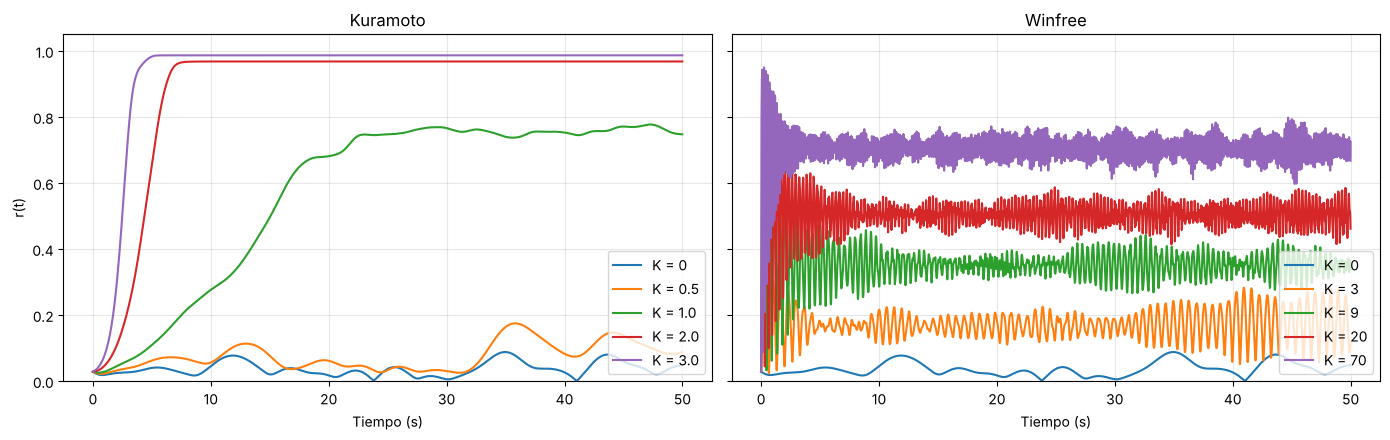

r promedio en los últimos 10 s
  Kuramoto  K =    0: r = 0.043 (oscila entre 0.00 y 0.08)
  Kuramoto  K =  0.5: r = 0.106 (oscila entre 0.07 y 0.15)
  Kuramoto  K =  1.0: r = 0.761 (oscila entre 0.74 y 0.78)


  Kuramoto  K =  2.0: r = 0.968 (oscila entre 0.97 y 0.97)
  Kuramoto  K =  3.0: r = 0.987 (oscila entre 0.99 y 0.99)
  Winfree   K =    0: r = 0.043 (oscila entre 0.00 y 0.08)
  Winfree   K =    3: r = 0.178 (oscila entre 0.05 y 0.28)


  Winfree   K =    9: r = 0.352 (oscila entre 0.28 y 0.43)
  Winfree   K =   20: r = 0.506 (oscila entre 0.42 y 0.59)
  Winfree   K =   70: r = 0.706 (oscila entre 0.60 y 0.80)


In [2]:
K_KURAMOTO = [0, 0.5, 1.0, 2.0, 3.0]
K_WINFREE = [0, 3, 9, 20, 70]
sim_k = {K: simular(derivada_kuramoto, K) for K in K_KURAMOTO}
sim_w = {K: simular(derivada_winfree, K) for K in K_WINFREE}

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for eje, sims, titulo in [(ejes[0], sim_k, 'Kuramoto'), (ejes[1], sim_w, 'Winfree')]:
    for K, h in sims.items():
        eje.plot(tiempo, orden(h), label=f'K = {K}', lw=1.5)
    eje.set_title(titulo)
    eje.set_xlabel('Tiempo (s)')
    eje.set_ylim(0, 1.05)
    eje.grid(alpha=0.3)
    eje.legend(loc='lower right')
ejes[0].set_ylabel('r(t)')
plt.tight_layout()
plt.show()

print('r promedio en los últimos 10 s')
for nombre, sims in [('Kuramoto', sim_k), ('Winfree', sim_w)]:
    for K, h in sims.items():
        r = orden(h)[-1000:]
        print(f'  {nombre:9} K = {K:>4}: r = {r.mean():.3f} (oscila entre {r.min():.2f} y {r.max():.2f})')

### Fases al final de la simulación

Cada punto es una célula en el círculo unitario: un arco estrecho indica sincronía; puntos repartidos en todo el círculo, desorden.

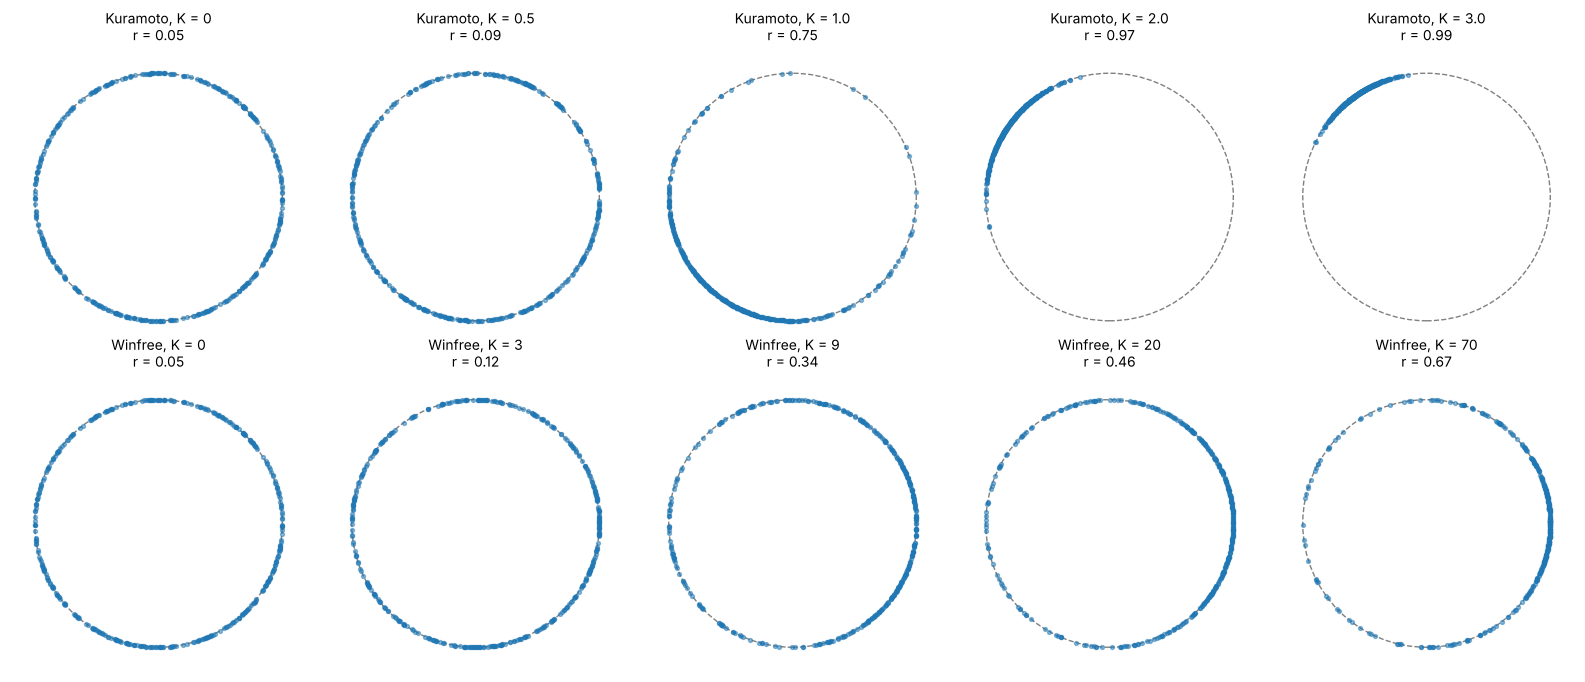

In [3]:
fig, ejes = plt.subplots(2, 5, figsize=(16, 6.8))
for fila, (sims, nombre) in enumerate([(sim_k, 'Kuramoto'), (sim_w, 'Winfree')]):
    for col, (K, h) in enumerate(sims.items()):
        eje = ejes[fila, col]
        final = h[-1]
        eje.add_patch(plt.Circle((0, 0), 1, fill=False, color='gray', ls='--'))
        eje.scatter(np.cos(final), np.sin(final), s=8, alpha=0.5)
        eje.set_title(f'{nombre}, K = {K}\nr = {orden(h[-1:])[0]:.2f}', fontsize=10)
        eje.set_xlim(-1.2, 1.2)
        eje.set_ylim(-1.2, 1.2)
        eje.set_aspect('equal')
        eje.axis('off')
plt.tight_layout()
plt.show()

### La red de células en tres momentos

Las 400 células acomodadas en una cuadrícula, coloreadas por el seno de su fase, para los casos con más acoplamiento de cada modelo. Reemplaza la animación: cuando la red se sincroniza, el color se vuelve uniforme.

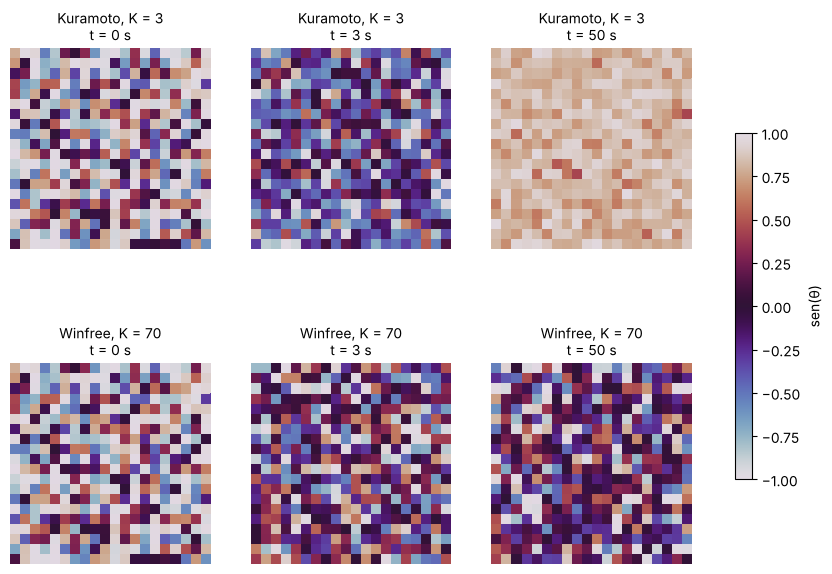

In [4]:
instantes = [0, 300, MUESTRAS - 1]
fig, ejes = plt.subplots(2, 3, figsize=(11, 7.5))
for fila, (h, nombre) in enumerate([(sim_k[3.0], 'Kuramoto, K = 3'), (sim_w[70], 'Winfree, K = 70')]):
    for col, t in enumerate(instantes):
        eje = ejes[fila, col]
        im = eje.imshow(np.sin(h[t]).reshape(20, 20), cmap='twilight', vmin=-1, vmax=1)
        eje.set_title(f'{nombre}\nt = {t * DT * CADA:.0f} s', fontsize=10)
        eje.axis('off')
fig.colorbar(im, ax=ejes, shrink=0.6, label='sen(θ)')
plt.show()

### Transición a la sincronía

Barrido fino de K para los dos modelos, con el valor crítico teórico de Kuramoto.

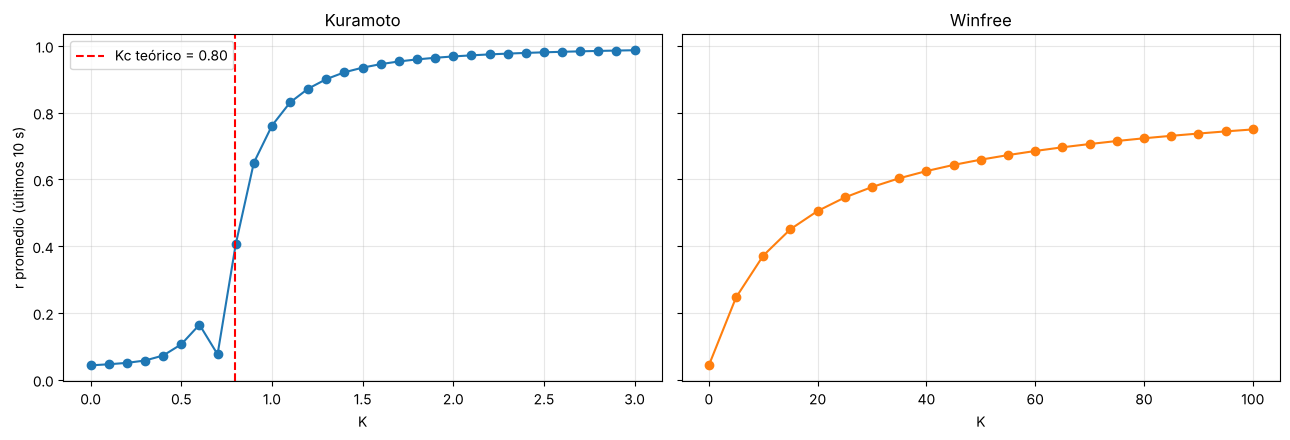

Kuramoto: r supera 0,5 por primera vez en K = 0.9
Winfree:  r supera 0,5 por primera vez en K = 20


In [5]:
barrido_k = np.round(np.arange(0, 3.01, 0.1), 2)
barrido_w = np.arange(0, 101, 5)
r_k = [orden(simular(derivada_kuramoto, K))[-1000:].mean() for K in barrido_k]
r_w = [orden(simular(derivada_winfree, K))[-1000:].mean() for K in barrido_w]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ejes[0].plot(barrido_k, r_k, 'o-')
ejes[0].axvline(KC_TEORICO, color='red', ls='--', label=f'Kc teórico = {KC_TEORICO:.2f}')
ejes[0].set_title('Kuramoto')
ejes[0].legend()
ejes[1].plot(barrido_w, r_w, 'o-', color='tab:orange')
ejes[1].set_title('Winfree')
for eje in ejes:
    eje.set_xlabel('K')
    eje.grid(alpha=0.3)
ejes[0].set_ylabel('r promedio (últimos 10 s)')
plt.tight_layout()
plt.show()

primero_k = barrido_k[np.argmax(np.array(r_k) > 0.5)]
primero_w = barrido_w[np.argmax(np.array(r_w) > 0.5)]
print(f'Kuramoto: r supera 0,5 por primera vez en K = {primero_k}')
print(f'Winfree:  r supera 0,5 por primera vez en K = {primero_w}')

## 6. Análisis y conclusiones

**Kuramoto: una transición de fase nítida.** Con K = 0 y K = 0,5 las fases siguen repartidas en todo el círculo (r ≈ 0,04 y 0,11). Entre K = 0,7 y K = 1,0 el parámetro de orden salta de 0,08 a 0,76, justo alrededor del valor crítico que predice la teoría (Kc ≈ 0,80); por encima de 2 la red queda casi completamente sincronizada (r ≈ 0,97) en menos de 10 segundos. Cerca del umbral (K = 1,0) la sincronización tarda más de 20 segundos en asentarse: el sistema se frena cerca de la transición.

**Winfree: sincronía gradual y pulsante.** No hay un salto: r crece de forma continua con K y se acerca a 0,75 recién en K = 100. Con P = 1 + cos θ y Z = 1 − cos θ, ambas funciones son no negativas, así que el acoplamiento solo acelera a los osciladores, y lo hace más donde Z es grande (lejos de θ = 0). Por eso, aun cuando las células forman un grupo, las fases se comprimen y se estiran a lo largo de cada ciclo, y r oscila rápidamente alrededor de su valor medio en lugar de estabilizarse.

**Escalas de K.** El valor de K en el que r supera 0,5 (0,9 en Kuramoto y 20 en Winfree) no indica que un modelo necesite «más» acoplamiento que el otro: los términos de acoplamiento tienen formas distintas y no son comparables directamente.

**Lectura biológica.** Kuramoto describe bien la aparición de un ritmo común estable a partir de células con frecuencias distintas, y su transición abrupta sugiere que pequeñas pérdidas de acoplamiento cerca del umbral pueden desorganizar el ritmo. Winfree, con pulsos y una sensibilidad que depende de la fase, produce un orden parcial y fluctuante, más parecido a la variabilidad de un tejido real, pero también más difícil de analizar.

**Limitaciones.** El acoplamiento es global; en el nodo sinoauricular cada célula se conecta solo con sus vecinas, lo que haría más lenta la sincronización y permitiría ondas y patrones espaciales. Además, las conclusiones sobre Winfree dependen de la elección de P y Z.